# 5. 🧭 Bring an edit back home

[All tutorials](https://github.com/bateni1380/landpy/tree/master/tutorials) · [Open in Colab](https://colab.research.google.com/github/bateni1380/landpy/blob/master/tutorials/5-crops-and-perspective.ipynb)

## Goal

Keep an AR effect aligned while cropping or straightening a tilted surface. By the end, you can use **retrace()** to return an edited rectangle or perspective crop to its original position.

## Setup

Run all cells from top to bottom in a fresh kernel. The setup cell installs Landpy 0.1.0 if needed. A CPU is enough. Python 3.10+ is supported; no model downloads are needed here.

In [1]:
import importlib.metadata
import subprocess
import sys
try:
    installed = importlib.metadata.version('landpy')
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != '0.1.0':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'landpy==0.1.0'])
import numpy as np
from landpy import ImageLand, MarksLand, SquareMarks, QuadMarks, Filter, Debugger


## Steps

### 1. Crop with bounds outside the image

Rectangle upper bounds are exclusive. Fractional crop minima round down; maxima round up. Out-of-canvas pixels use the fill color.

In [2]:
rows, columns = np.indices((120, 180))
pixels = np.stack((columns / 179, rows / 119, np.full(rows.shape, .35)), axis=-1)
image = ImageLand(pixels)

region = SquareMarks(-15, 100, 20, 160, shape=image.shape)
cropped = image.copy().zoom(region, save_trace=True, fill_color=(30, 30, 30))
debugger = Debugger(visual_debug=True)
debugger.save_image(image.get_image(), 'Original')
debugger.save_image(cropped.get_image(), 'Crop with padding')

### 2. Paste edited crop pixels back

Retracing a crop brings the edited pixels back onto the saved canvas. The surrounding pixels are retained. Fully transparent crop pixels leave the saved canvas intact. Undo a checkpoint instead when you want to discard every edit.

The gray strip belongs to the padded crop, outside the original canvas. After retrace, only the overlap is pasted back. The comparison below makes that boundary visible.

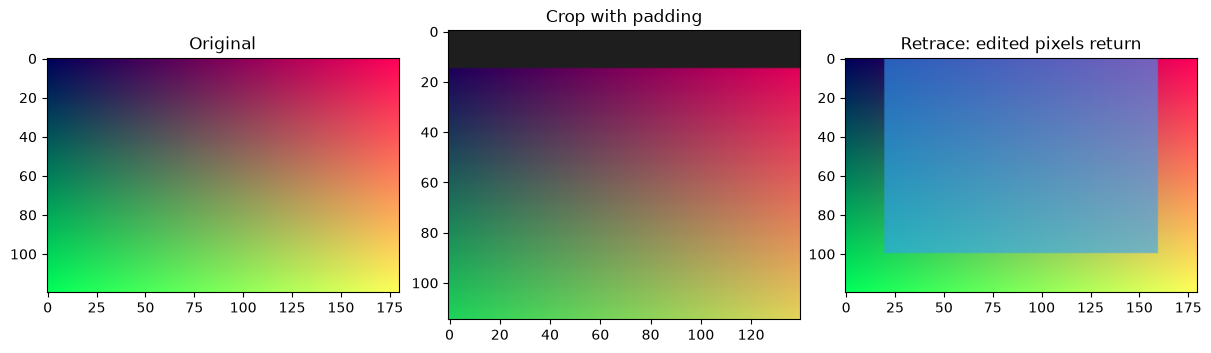

In [3]:
cropped.implant_filter(Filter('#30a0ff', .6)).retrace()
debugger.save_image(cropped.get_image(), 'Retrace: edited pixels return')
debugger.log_saved_images();

### 3. Rectify a perspective region

QuadMarks orders a convex set of four corners clockwise starting at top-left. Image, heat and landmark zooms share the same projective matrix. A rotated SquareMarks must first become a QuadMarks.

For an AR label on a slanted surface, straighten the region, edit it, and retrace the perspective transform. Resampling can soften edges; use checkpoints when you need exact restoration.

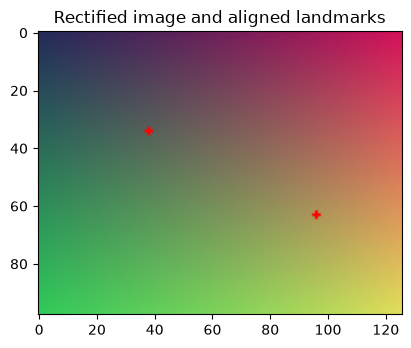

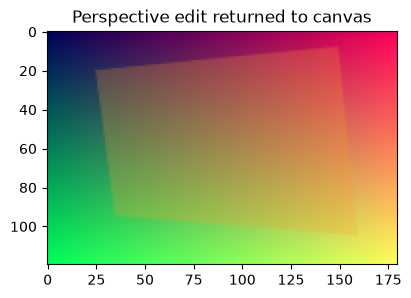

In [4]:
quad = QuadMarks((20, 25), (8, 150), (105, 160), (95, 35), shape=image.shape)
points = MarksLand([[45, 60], [70, 120]], shape=image.shape)
zoomed_image = image.copy().zoom(quad, save_trace=True)
zoomed_points = points.copy().zoom(quad, save_trace=True)
zoomed_heat = quad.to_heat().zoom(quad, save_trace=True)
(zoomed_image + zoomed_points).show('Rectified image and aligned landmarks')
zoomed_points.retrace()
zoomed_heat.retrace()
zoomed_image.implant_filter(Filter('#ffa030', .25)).retrace().show('Perspective edit returned to canvas');

## Checks

In [5]:
assert cropped.shape == image.shape
np.testing.assert_array_equal(cropped.get_image()[110:, :], image.get_image()[110:, :])
np.testing.assert_allclose(zoomed_points.get_marks(), points.get_marks(), atol=1e-10)
assert zoomed_heat.shape == image.shape
assert zoomed_image.shape == image.shape

## Take it further 🚀

The effect can find its way home. Next, place a transparent image instead of a flat color.

[Choose the next notebook](https://github.com/bateni1380/landpy/tree/master/tutorials)

**Try it:** Move one corner of the quad and watch the returned effect follow the new surface.

➡️ **[Continue to notebook 6](https://github.com/bateni1380/landpy/blob/master/tutorials/6-image-compositing.ipynb)**

[← Previous lesson](https://github.com/bateni1380/landpy/blob/master/tutorials/4-history-and-debugging.ipynb)